In [1]:
import numpy as np
import spectral.io.envi as envi
import pandas as pd
import matplotlib.pyplot as plt
import os

In [2]:
# Antes do pré-processamento (imagem HSI original)
input_hdr_path = '/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/hsi_original/351_1_240506-160920/capture/351_1_240506-160920.hdr'

# Depois do pré-processamento (CSV com índices espectrais)
preprocessed_csv_path = '/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/feature_engineering/data_indices_espectrais.csv'

In [3]:
img_spectral = envi.open(input_hdr_path)
img_array = img_spectral.load()
img_array = np.array(img_array)

altura, largura, n_bandas = img_array.shape
n_amostras = altura * largura

# Reshape para matriz [n_amostras × n_bandas]
espectros_matriz = img_array.reshape(n_amostras, n_bandas)

/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/.venv/lib/python3.11/site-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


In [4]:
df_pre = pd.read_csv(preprocessed_csv_path)

# Identificar colunas de índices (ajuste caso tenha nomes diferentes)
indices_cols = [col for col in df_pre.columns if 'indice' in col]

# -------------------
# Plotagem
# -------------------
n_plot = 5  # número de amostras para plotar

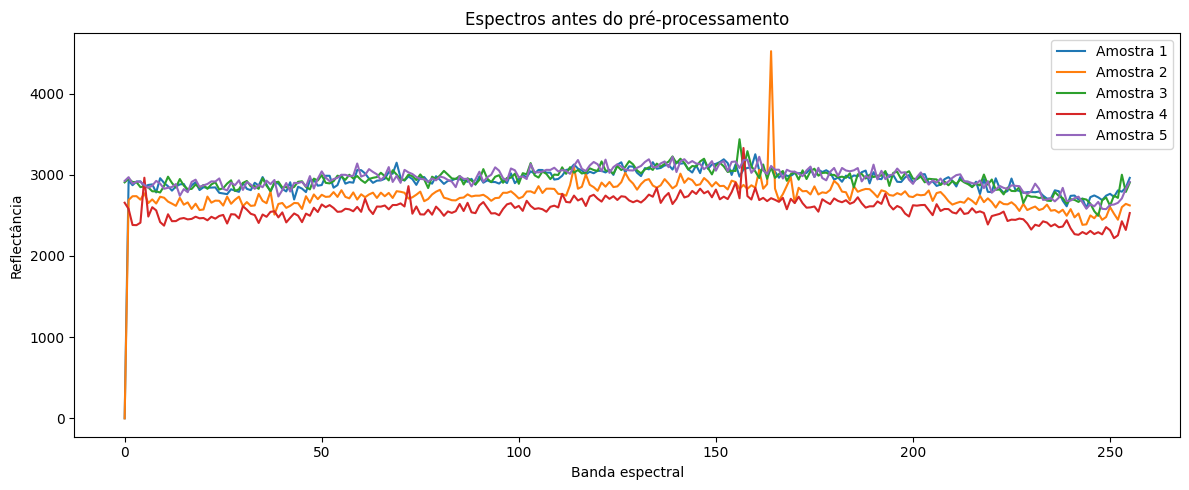

In [5]:
plt.figure(figsize=(12, 5))
for i in range(n_plot):
    plt.plot(espectros_matriz[i, :], label=f'Amostra {i+1}')
plt.title('Espectros antes do pré-processamento')
plt.xlabel('Banda espectral')
plt.ylabel('Reflectância')
plt.legend()
plt.tight_layout()

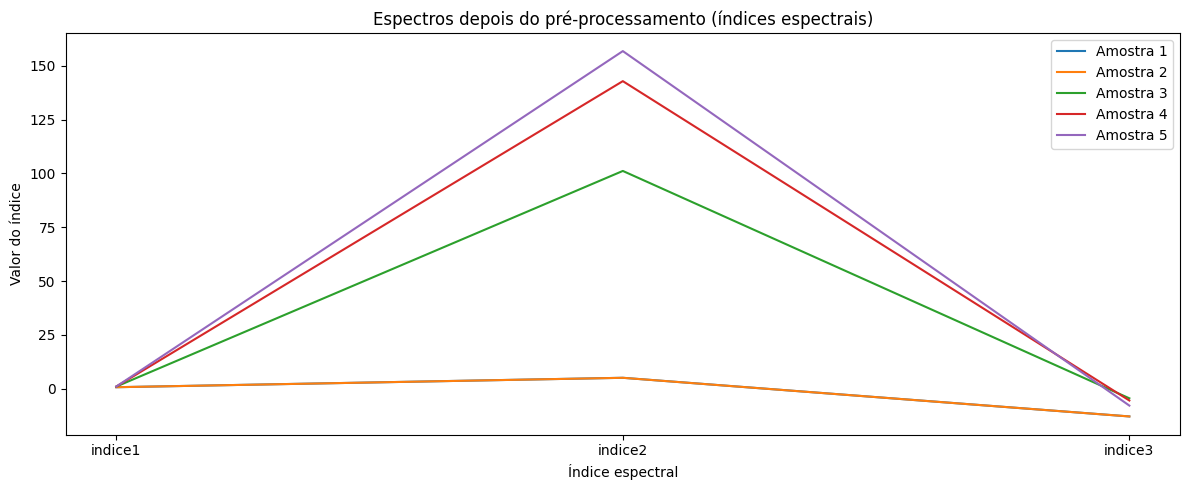

In [6]:
# Depois do pré-processamento
plt.figure(figsize=(12, 5))
for i in range(n_plot):
    plt.plot(df_pre[indices_cols].iloc[i], label=f'Amostra {i+1}')
plt.title('Espectros depois do pré-processamento (índices espectrais)')
plt.xlabel('Índice espectral')
plt.ylabel('Valor do índice')
plt.legend()
plt.tight_layout()